In [1]:
!pip install scikit-fuzzy

COMPARACAO DOS METODOS DE DEFUZZIFICACAO

Metodo: CENTROID
Impacto=  0 | Explorabilidade=   0 | Urgencia=10.00%
Impacto=100 | Explorabilidade=  10 | Urgencia=90.00%
Impacto= 50 | Explorabilidade=   5 | Urgencia=68.33%
Impacto= 80 | Explorabilidade=   9 | Urgencia=88.33%

Metodo: MOM
Impacto=  0 | Explorabilidade=   0 | Urgencia=0.00%
Impacto=100 | Explorabilidade=  10 | Urgencia=100.00%
Impacto= 50 | Explorabilidade=   5 | Urgencia=70.00%
Impacto= 80 | Explorabilidade=   9 | Urgencia=92.50%


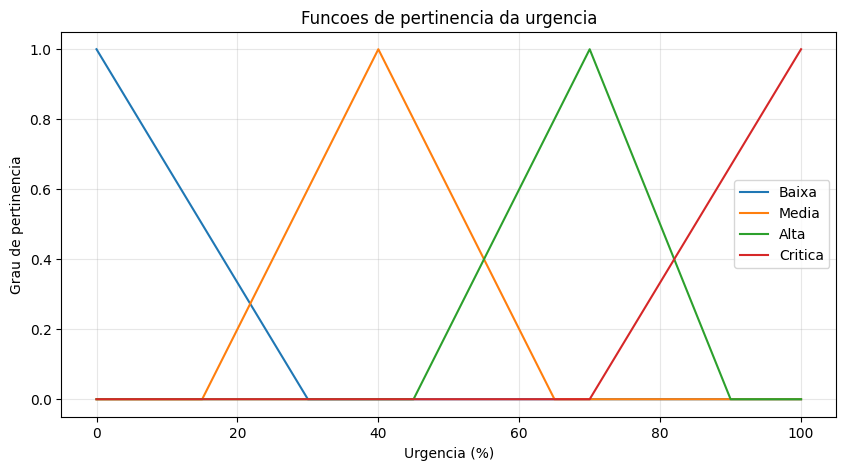

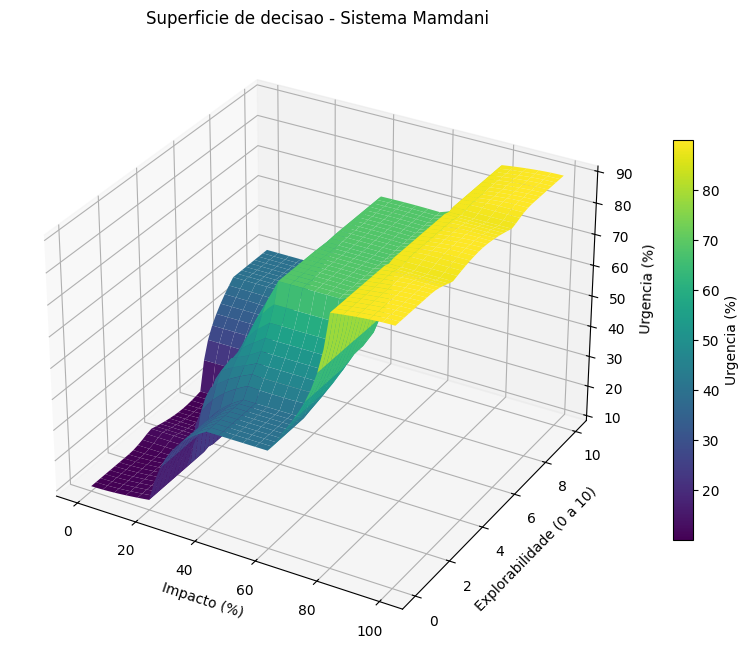

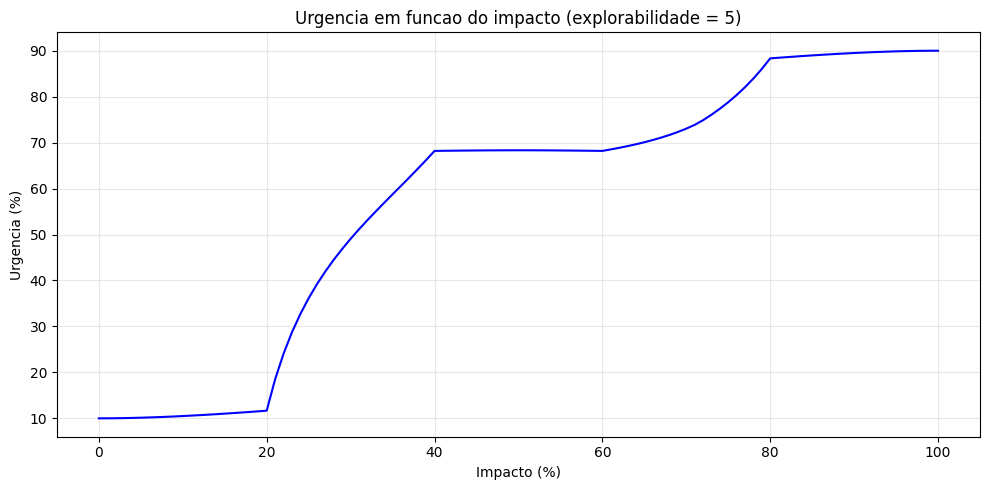

In [5]:


import os
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl

# ------------------------------------------------------------
# 1. DEFINICAO DAS VARIAVEIS
# ------------------------------------------------------------

# Impacto: de 0 a 100
impacto = ctrl.Antecedent(np.arange(0, 101, 1), "impacto")

# Explorabilidade: de 0 a 10
explorabilidade = ctrl.Antecedent(
    np.arange(0, 10.01, 0.1), "explorabilidade"
)

# Urgencia: de 0 a 100
urgencia = ctrl.Consequent(np.arange(0, 101, 1), "urgencia")

# ------------------------------------------------------------
# 2. FUNCOES DE PERTINENCIA DAS ENTRADAS
# ------------------------------------------------------------

# Impacto: Baixo, Medio e Alto
impacto["baixo"] = fuzz.trimf(impacto.universe, [0, 0, 40])
impacto["medio"] = fuzz.trimf(impacto.universe, [20, 50, 80])
impacto["alto"] = fuzz.trimf(impacto.universe, [60, 100, 100])

# Explorabilidade: Baixa, Moderada e Alta
explorabilidade["baixa"] = fuzz.trapmf(
    explorabilidade.universe, [0, 0, 2, 4]
)
explorabilidade["moderada"] = fuzz.trimf(
    explorabilidade.universe, [2, 5, 8]
)
explorabilidade["alta"] = fuzz.trapmf(
    explorabilidade.universe, [6, 8, 10, 10]
)

# ------------------------------------------------------------
# 3. FUNCOES DE PERTINENCIA DA SAIDA
# ------------------------------------------------------------

# Tres primeiras categorias iguais nos dois experimentos.
urgencia["baixa"] = fuzz.trimf(
    urgencia.universe, [0, 0, 30]
)
urgencia["media"] = fuzz.trimf(
    urgencia.universe, [15, 40, 65]
)
urgencia["alta"] = fuzz.trimf(
    urgencia.universe, [45, 70, 90]
)

# Abordagem A: urgencia critica com trapezio na borda superior.
# O maximo de pertinencia fica concentrado em 100.
urgencia["critica"] = fuzz.trapmf(
    urgencia.universe, [70, 100, 100, 100]
)

# ------------------------------------------------------------
# 4. MATRIZ COMPLETA DE REGRAS 3 X 3
# ------------------------------------------------------------

regras = [
    # Impacto baixo
    ctrl.Rule(
        impacto["baixo"] & explorabilidade["baixa"],
        urgencia["baixa"]
    ),
    ctrl.Rule(
        impacto["baixo"] & explorabilidade["moderada"],
        urgencia["baixa"]
    ),
    ctrl.Rule(
        impacto["baixo"] & explorabilidade["alta"],
        urgencia["media"]
    ),

    # Impacto medio
    ctrl.Rule(
        impacto["medio"] & explorabilidade["baixa"],
        urgencia["media"]
    ),
    ctrl.Rule(
        impacto["medio"] & explorabilidade["moderada"],
        urgencia["alta"]
    ),
    ctrl.Rule(
        impacto["medio"] & explorabilidade["alta"],
        urgencia["alta"]
    ),

    # Impacto alto
    ctrl.Rule(
        impacto["alto"] & explorabilidade["baixa"],
        urgencia["critica"]
    ),
    ctrl.Rule(
        impacto["alto"] & explorabilidade["moderada"],
        urgencia["critica"]
    ),
    ctrl.Rule(
        impacto["alto"] & explorabilidade["alta"],
        urgencia["critica"]
    ),
]

# ------------------------------------------------------------
# 5. FUNCAO PARA CRIAR E EXECUTAR O SISTEMA
# ------------------------------------------------------------

def criar_sistema(metodo="centroid"):
    """
    Cria um sistema Mamdani com o metodo escolhido:
    'centroid' ou 'mom'.
    """
    urgencia.defuzzify_method = metodo

    controle = ctrl.ControlSystem(regras)
    simulador = ctrl.ControlSystemSimulation(controle)

    return simulador


def calcular_saida(simulador, valor_impacto, valor_explorabilidade):
    """Calcula a urgencia para duas entradas."""
    simulador.input["impacto"] = float(valor_impacto)
    simulador.input["explorabilidade"] = float(
        valor_explorabilidade
    )
    simulador.compute()

    return float(simulador.output["urgencia"])


# ------------------------------------------------------------
# 6. TESTE DOS EXTREMOS: CENTROIDE X MOM
# ------------------------------------------------------------

entradas_teste = [
    (0, 0),
    (100, 10),
    (50, 5),
    (80, 9),
]

print("=" * 60)
print("COMPARACAO DOS METODOS DE DEFUZZIFICACAO")
print("=" * 60)

for metodo in ["centroid", "mom"]:
    simulador = criar_sistema(metodo)

    print(f"\nMetodo: {metodo.upper()}")

    for i, e in entradas_teste:
        try:
            resultado = calcular_saida(simulador, i, e)
            print(
                f"Impacto={i:3} | Explorabilidade={e:4} "
                f"| Urgencia={resultado:.2f}%"
            )
        except Exception as erro:
            print(f"Erro para as entradas ({i}, {e}): {erro}")

# ------------------------------------------------------------
# 7. GRAFICO DAS FUNCOES DE PERTINENCIA DA SAIDA
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

for nome in ["baixa", "media", "alta", "critica"]:
    plt.plot(
        urgencia.universe,
        urgencia[nome].mf,
        label=nome.capitalize()
    )

plt.title("Funcoes de pertinencia da urgencia")
plt.xlabel("Urgencia (%)")
plt.ylabel("Grau de pertinencia")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# ------------------------------------------------------------
# 8. SUPERFICIE DE DECISAO 3D
# ------------------------------------------------------------

# Usamos o metodo centroide para visualizar a superficie.
simulador = criar_sistema("centroid")

valores_impacto = np.arange(0, 101, 2)
valores_explorabilidade = np.arange(0, 10.01, 0.25)

X, Y = np.meshgrid(
    valores_impacto,
    valores_explorabilidade
)
Z = np.zeros_like(X, dtype=float)

for linha in range(Y.shape[0]):
    for coluna in range(X.shape[1]):
        Z[linha, coluna] = calcular_saida(
            simulador,
            X[linha, coluna],
            Y[linha, coluna]
        )

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")

superficie = ax.plot_surface(
    X, Y, Z,
    cmap="viridis",
    edgecolor="none",
    antialiased=True
)

ax.set_title("Superficie de decisao - Sistema Mamdani")
ax.set_xlabel("Impacto (%)")
ax.set_ylabel("Explorabilidade (0 a 10)")
ax.set_zlabel("Urgencia (%)")

fig.colorbar(
    superficie,
    ax=ax,
    shrink=0.65,
    label="Urgencia (%)"
)


# ------------------------------------------------------------
# 9. GRAFICO DE SAIDA PARA EXPLORABILIDADE FIXA
# ------------------------------------------------------------

simulador = criar_sistema("centroid")
impactos = np.arange(0, 101, 1)
saidas = []

for valor in impactos:
    saidas.append(calcular_saida(simulador, valor, 5))

plt.figure(figsize=(10, 5))
plt.plot(impactos, saidas, color="blue")
plt.title("Urgencia em funcao do impacto (explorabilidade = 5)")
plt.xlabel("Impacto (%)")
plt.ylabel("Urgencia (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

